# ComfyWatt: Predicting Indoor Comfort in Smart Buildings

**Team ComfyWatt:** Youssef Sabiri, Abdellah Elouazzani, Taoufyq Elansari (hackathon project, 2024)

ComfyWatt is a smart-building concept that monitors indoor environmental quality and adjusts building systems to keep occupants comfortable while using less energy. This notebook is the machine-learning part. It trains deep learning models to predict three comfort indicators of a room:

- **air temperature**
- **illuminance** (light level)
- **indoor CO₂**

The inputs are the room's other sensor readings: HVAC operation, humidity, noise, particulate matter, outdoor weather and occupancy. It compares three recurrent architectures: **LSTM**, **GRU** and **Bidirectional LSTM + dense layers**.

> Sections 1 and 2 (dataset description, loading and the missing-data chart) are adapted from the example notebook published by the ROBOD dataset authors. Sections 3 onwards are the team's own work.

## 1. The ROBOD dataset

[ROBOD](https://github.com/ideas-lab-nus/robod) (Room-level Occupancy and Building Operation Dataset) was collected by researchers at the National University of Singapore in the SDE4 building. SDE4 is a net-zero energy academic building. The dataset covers five rooms from September to December 2021 at 5-minute resolution: two lecture rooms, two offices and a library space. It includes indoor environmental quality, Wi-Fi connected devices, energy use, HVAC operations, outdoor weather and ground-truth occupancy.

This notebook models **Room 5 (the library space)**, which has 47 days of data.

**Getting the data:** download the `Data/` folder from the [ROBOD repository](https://github.com/ideas-lab-nus/robod) (or from [figshare](https://doi.org/10.6084/m9.figshare.19234530.v3)). Place the five `combined_Room*.csv` files in `data/robod/` at the root of this repository.

**Citation:** Tekler, Z. D., et al. "ROBOD, room-level occupancy and building operation dataset." *Building Simulation*, 2022. https://doi.org/10.1007/s12273-022-0925-9

In [1]:
import os
import random
from copy import deepcopy
from pathlib import Path

import matplotlib.pyplot as plt
import missingno as msno
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.layers import GRU, LSTM, Bidirectional, Dense, Dropout, Input
from tensorflow.keras.models import Sequential

# Fixing the random seeds so results are reproducible between runs
SEED = 42
tf.keras.utils.set_random_seed(SEED)

# Finding the data folder whether the notebook is run from the repo root or from notebooks/
DATA_DIR = next((p for p in [Path("data/robod"), Path("../data/robod")] if p.exists()), None)
if DATA_DIR is None:
    raise FileNotFoundError("ROBOD data not found: put the combined_Room*.csv files in data/robod/ (see section 1)")

OUTPUT_DIR = DATA_DIR.parent.parent / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

I0000 00:00:1790721959.152712     568 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1790721959.199929     568 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1790721960.594019     568 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
# Load the ROBOD dataset for each room
room_names = ["Room1", "Room2", "Room3", "Room4", "Room5"]
data_dict = {}

for room in room_names:
    data_dict[room] = {}
    data_dict[room]["raw"] = pd.read_csv(DATA_DIR / f"combined_{room}.csv")
    raw = data_dict[room]["raw"]
    print(f"{room}: {raw.shape[0]} rows, {raw.shape[1]} columns, {raw.isna().sum().sum()} missing values")

Room1: 8352 rows, 28 columns, 122 missing values
Room2: 8352 rows, 28 columns, 180 missing values
Room3: 8352 rows, 36 columns, 78 missing values
Room4: 13536 rows, 36 columns, 78 missing values
Room5: 13536 rows, 36 columns, 5250 missing values


## 2. Visualising missing data

Some sensors had errors or gaps, so we start by visualising the missing data points in each room (white = missing).

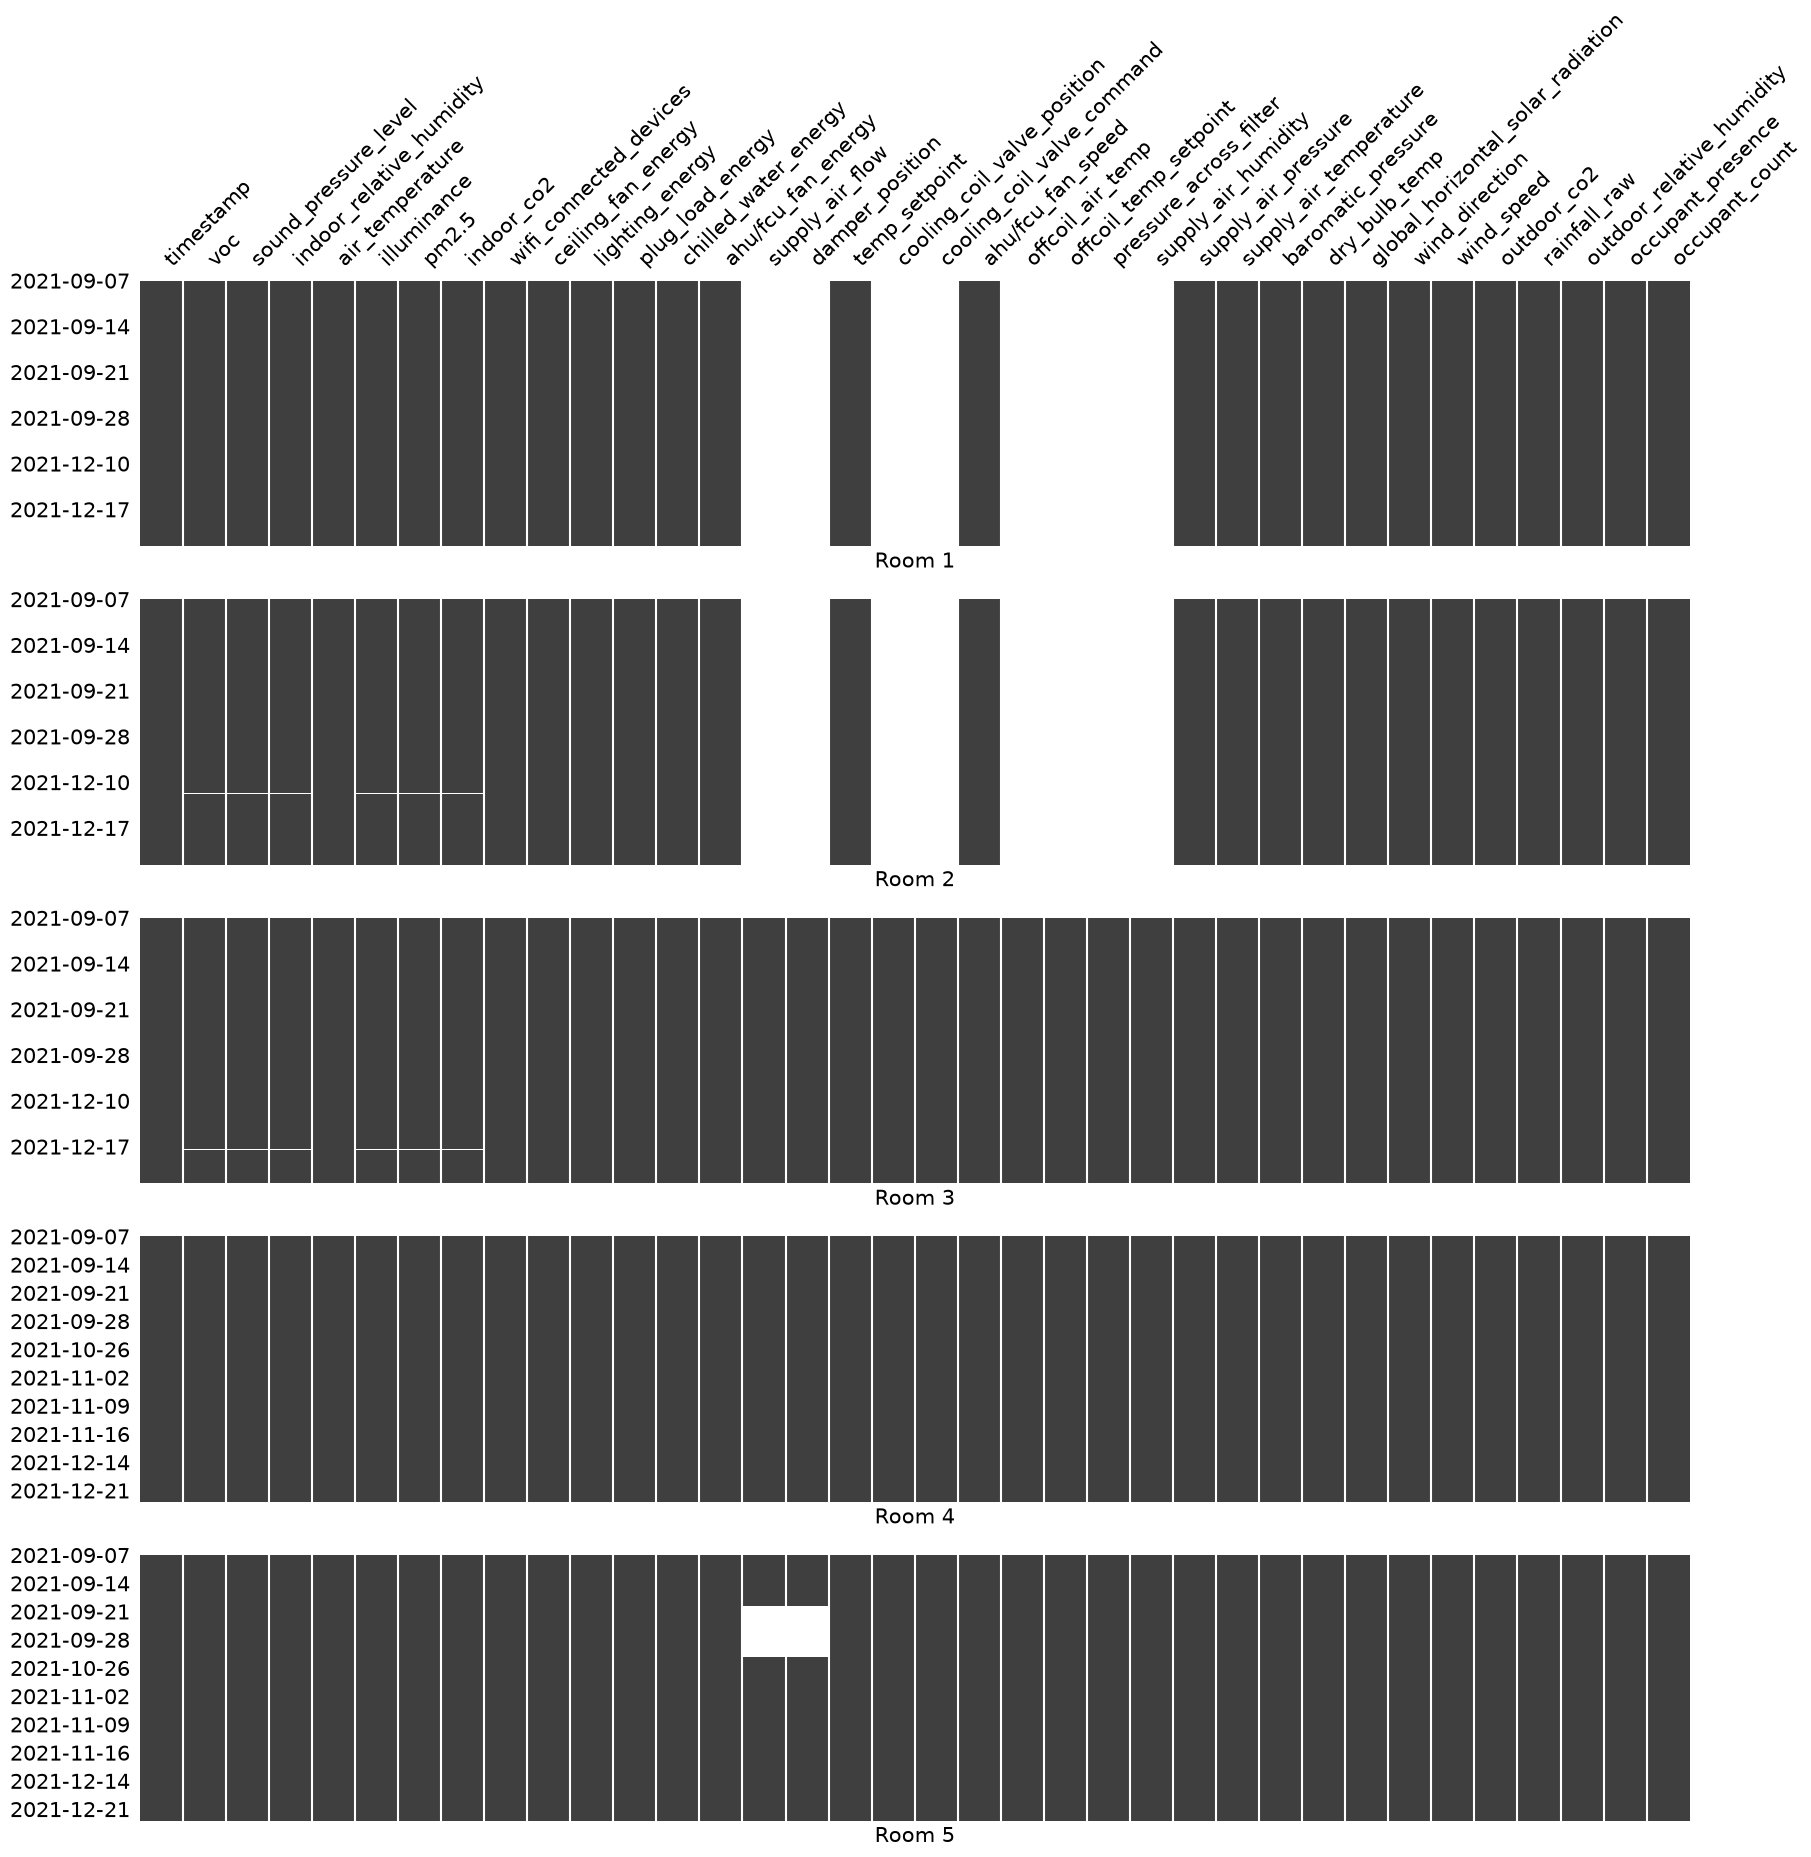

In [3]:
ROOM1_2_COLUMNS = ['timestamp', 'voc', 'sound_pressure_level', 'indoor_relative_humidity',  'air_temperature',
                   'illuminance', 'pm2.5', 'indoor_co2', 'wifi_connected_devices', 'ceiling_fan_energy',
                   'lighting_energy', 'plug_load_energy', 'chilled_water_energy', 'fcu_fan_energy',
                   'supply_air_flow', 'damper_position', 'temp_setpoint',  'cooling_coil_valve_position',
                   'cooling_coil_valve_command', 'fcu_fan_speed', 'offcoil_air_temp',
                   'offcoil_temp_setpoint', 'pressure_across_filter', 'supply_air_humidity',
                   'supply_air_pressure', 'supply_air_temperature', 'baromatic_pressure', 'dry_bulb_temp',
                   'global_horizontal_solar_radiation', 'wind_direction', 'wind_speed', 'outdoor_co2',
                   'rainfall_raw', 'outdoor_relative_humidity',  'occupant_presence', 'occupant_count']

ROOM3_5_COLUMNS = ['timestamp', 'voc', 'sound_pressure_level', 'indoor_relative_humidity',  'air_temperature',
                   'illuminance', 'pm2.5', 'indoor_co2', 'wifi_connected_devices', 'ceiling_fan_energy',
                   'lighting_energy', 'plug_load_energy', 'chilled_water_energy', 'ahu_fan_energy',
                   'supply_air_flow', 'damper_position', 'temp_setpoint',  'cooling_coil_valve_position',
                   'cooling_coil_valve_command', 'ahu_fan_speed', 'offcoil_air_temp',
                   'offcoil_temp_setpoint', 'pressure_across_filter', 'supply_air_humidity',
                   'supply_air_pressure', 'supply_air_temperature', 'baromatic_pressure', 'dry_bulb_temp',
                   'global_horizontal_solar_radiation', 'wind_direction', 'wind_speed', 'outdoor_co2',
                   'rainfall_raw', 'outdoor_relative_humidity',  'occupant_presence', 'occupant_count']

def plot_missing_data():
    fig, axs = plt.subplots(len(room_names), figsize=(20,20))

    for i in range(len(room_names)):
        room_name = room_names[i]
        raw_room_data1 = deepcopy(data_dict[room_name]["raw"])
        raw_room_data2 = deepcopy(data_dict[room_name]["raw"])
        raw_room_data1[["date","time","utc_offset"]] = raw_room_data1["timestamp"].str.split(' ',expand=True)

        if room_name in ["Room1", "Room2"]:
            DATA_COLUMNS = ROOM1_2_COLUMNS
        else:
            DATA_COLUMNS = ROOM3_5_COLUMNS

        for col in DATA_COLUMNS:
            if col not in list(raw_room_data2.columns):
                raw_room_data2[col] = np.nan
        raw_room_data2 = raw_room_data2[DATA_COLUMNS]
        if room_name in ["Room1", "Room2"]:
            raw_room_data2.rename(columns={"fcu_fan_speed":"ahu/fcu_fan_speed",
                                           "fcu_fan_energy":"ahu/fcu_fan_energy"},
                                  inplace=True)
        else:
            raw_room_data2.rename(columns={"ahu_fan_speed":"ahu/fcu_fan_speed",
                                           "ahu_fan_energy":"ahu/fcu_fan_energy"},
                                  inplace=True)

        msno.matrix(raw_room_data2, ax=axs[i], sparkline=False)
        axs[i].set_xlabel("Room {}".format(room_name[-1]), fontsize=15)
        if i == 0:
            axs[i].set_xticklabels(labels=list(raw_room_data2.columns), fontsize=15)
        else:
            axs[i].set_xticklabels(labels=[])
        axs[i].set_yticks(np.arange(0,len(raw_room_data1),288*5-1))
        axs[i].set_yticklabels([raw_room_data1.loc[i,"date"] for i in np.arange(0,len(raw_room_data1),288*5-1)],
                               fontsize=15)

    plt.savefig(OUTPUT_DIR / 'missing_data.png', dpi=150, bbox_inches="tight")

plot_missing_data()

## 3. Cleaning the data

We work on Room 5 (library). Missing values are filled with the mean of each column.

In [4]:
data = pd.read_csv(DATA_DIR / 'combined_Room5.csv')
data = data.drop(columns=['timestamp'])
# Handling missing values (simple imputation with the column mean)
data = data.fillna(data.mean())

## 4. Feature selection

We drop the energy-use columns, Wi-Fi device counts and VOC, keeping the sensor, HVAC, weather and occupancy features as model inputs.

In [5]:
# Drop the specified columns
columns_to_drop = [
    'voc', 'ceiling_fan_energy', 'lighting_energy',
    'plug_load_energy', 'chilled_water_energy', 'ahu_fan_energy',
    'wifi_connected_devices'
]
data = data.drop(columns=columns_to_drop)

## 5. Train / test split and normalization

The three comfort indicators are the targets and everything else is an input. 5% of the rows are held out for testing. Inputs and targets are standardized with scalers fitted on the training set only.

In [6]:
# Features and target variables
target_columns = ['air_temperature', 'illuminance', 'indoor_co2']
X = data.drop(columns=target_columns).values
y = data[target_columns].values
print(f"{X.shape[1]} input features, {len(target_columns)} targets, {len(data)} rows")

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.05, random_state=42)

# Normalize the data
scaler_X = StandardScaler()
X_train = scaler_X.fit_transform(X_train)
X_test = scaler_X.transform(X_test)

scaler_y = StandardScaler()
y_train = scaler_y.fit_transform(y_train)
y_test = scaler_y.transform(y_test)

# Reshape for recurrent layers: [samples, time steps, features]
X_train = X_train.reshape((X_train.shape[0], 1, X_train.shape[1]))
X_test = X_test.reshape((X_test.shape[0], 1, X_test.shape[1]))

25 input features, 3 targets, 13536 rows


## 6. Evaluation

Each model is scored on the test set in the original units (°C, lux, ppm) with MAE, RMSE and R², and its predictions are plotted against the true values.

In [7]:
results = []
target_labels = ['Air Temperature (°C)', 'Illuminance (lux)', 'Indoor CO2 (ppm)']

def evaluate_and_plot(model, name, history):
    y_pred = scaler_y.inverse_transform(model.predict(X_test, verbose=0))
    y_true = scaler_y.inverse_transform(y_test)

    for i, target in enumerate(target_columns):
        results.append({
            'Model': name,
            'Target': target,
            'MAE': mean_absolute_error(y_true[:, i], y_pred[:, i]),
            'RMSE': np.sqrt(mean_squared_error(y_true[:, i], y_pred[:, i])),
            'R2': r2_score(y_true[:, i], y_pred[:, i]),
        })
    print(pd.DataFrame([r for r in results if r['Model'] == name]).round(4).to_string(index=False))

    # Plotting the true and predicted values for each target
    fig, axes = plt.subplots(4, 1, figsize=(14, 13))
    for i, label in enumerate(target_labels):
        axes[i].plot(y_true[:, i], label=f'True', linewidth=1)
        axes[i].plot(y_pred[:, i], label=f'Predicted', linewidth=1)
        axes[i].set_ylabel(label)
        axes[i].legend(loc='upper right')
    axes[2].set_xlabel('Test samples')
    axes[3].plot(history.history['loss'], label='Training loss')
    axes[3].plot(history.history['val_loss'], label='Test loss')
    axes[3].set_xlabel('Epoch')
    axes[3].set_ylabel('MSE (scaled)')
    axes[3].legend()
    fig.suptitle(name)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f"predictions_{name.lower().replace(' ', '_').replace('+', 'plus')}.png", dpi=120)
    plt.show()

## 7. Models

### 7.1 LSTM

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 1, 100)         │        50,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1, 100)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 100)            │        80,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │           303 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 131,103 (512.12 KB)

 Trainable params: 131,103 (512.12 KB)

 Non-trainable params: 0 (0.00 B)

Model          Target     MAE     RMSE     R2
 LSTM air_temperature  0.0902   0.1342 0.9642
 LSTM     illuminance 91.1303 266.8894 0.6317
 LSTM      indoor_co2  5.8000   7.8934 0.9520


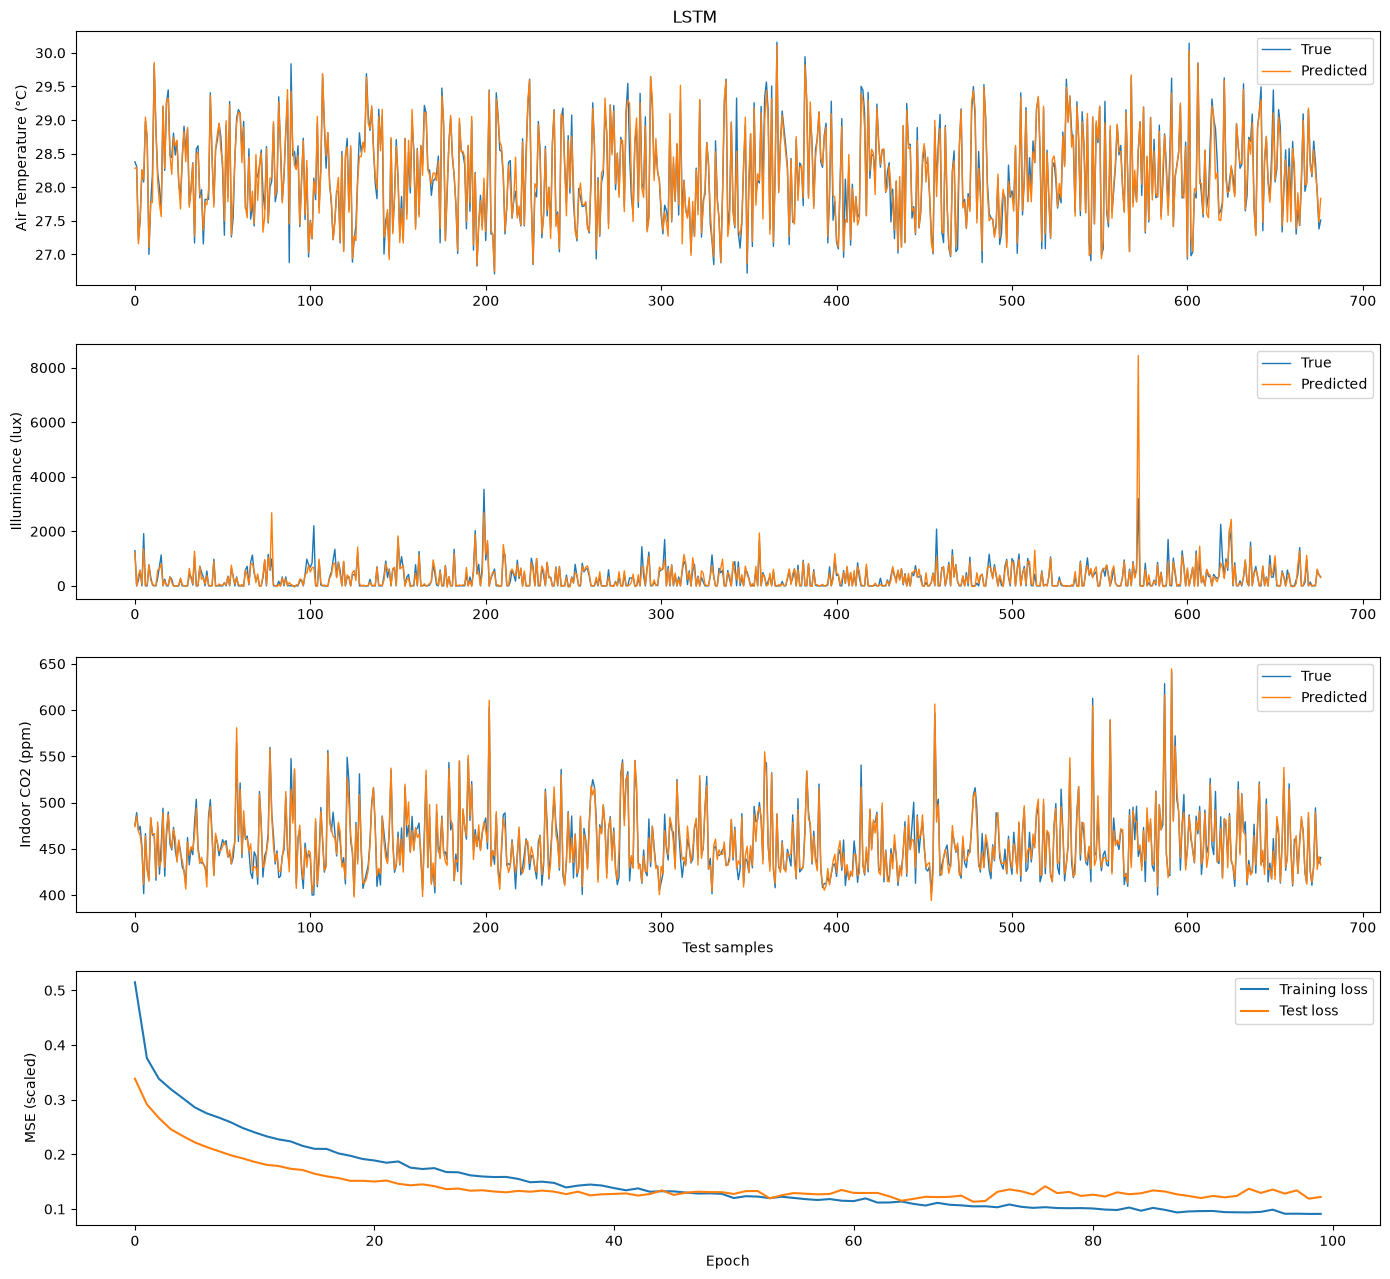

In [8]:
MODEL_NAME = 'LSTM'

# Build the LSTM model
model = Sequential()
model.add(Input(shape=(X_train.shape[1], X_train.shape[2])))
model.add(LSTM(100, return_sequences=True))
model.add(Dropout(0.2))
model.add(LSTM(100))
model.add(Dropout(0.2))
model.add(Dense(len(target_columns)))

model.compile(optimizer='adam', loss='mean_squared_error')
model.summary()

# Train the model
history = model.fit(X_train, y_train, epochs=100, batch_size=32,
                    validation_data=(X_test, y_test), verbose=0, shuffle=False)

evaluate_and_plot(model, MODEL_NAME, history)

### 7.2 GRU

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 1, 100)         │        38,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1, 100)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 100)            │        60,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           303 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 99,003 (386.73 KB)

 Trainable params: 99,003 (386.73 KB)

 Non-trainable params: 0 (0.00 B)

Model          Target     MAE     RMSE     R2
  GRU air_temperature  0.0940   0.1317 0.9655
  GRU     illuminance 88.4228 251.7831 0.6722
  GRU      indoor_co2  6.2186   8.6302 0.9426


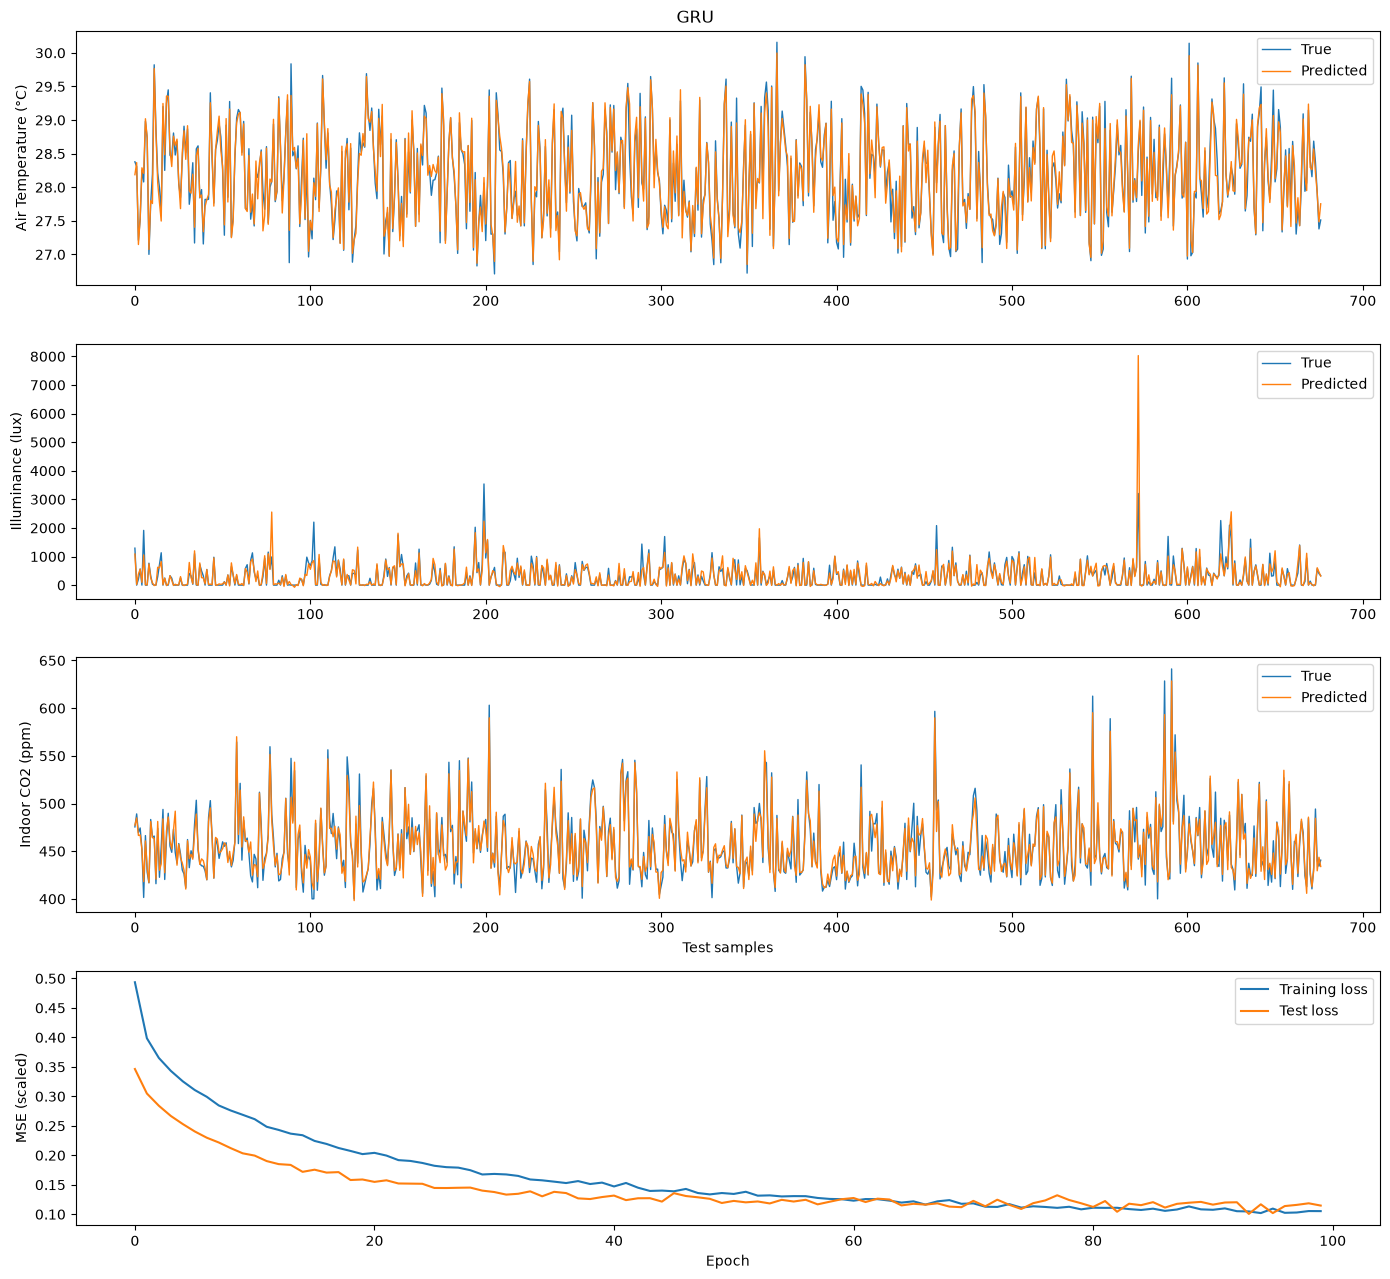

In [9]:
MODEL_NAME = 'GRU'

# Build the GRU model
model = Sequential()
model.add(Input(shape=(X_train.shape[1], X_train.shape[2])))
model.add(GRU(100, return_sequences=True))
model.add(Dropout(0.2))
model.add(GRU(100))
model.add(Dropout(0.2))
model.add(Dense(len(target_columns)))

model.compile(optimizer='adam', loss='mean_squared_error')
model.summary()

# Train the model
history = model.fit(X_train, y_train, epochs=100, batch_size=32,
                    validation_data=(X_test, y_test), verbose=0, shuffle=False)

evaluate_and_plot(model, MODEL_NAME, history)

### 7.3 Bidirectional LSTM + DNN

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional (Bidirectional)   │ (None, 1, 200)         │       100,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 1, 200)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 200)            │       240,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 200)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 100)            │        20,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 20)             │         2,020 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 3)              │            63 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 363,783 (1.39 MB)

 Trainable params: 363,783 (1.39 MB)

 Non-trainable params: 0 (0.00 B)

       Model          Target     MAE     RMSE     R2
BiLSTM + DNN air_temperature  0.0706   0.1090 0.9764
BiLSTM + DNN     illuminance 87.1911 355.7490 0.3456
BiLSTM + DNN      indoor_co2  4.8433   6.5127 0.9673


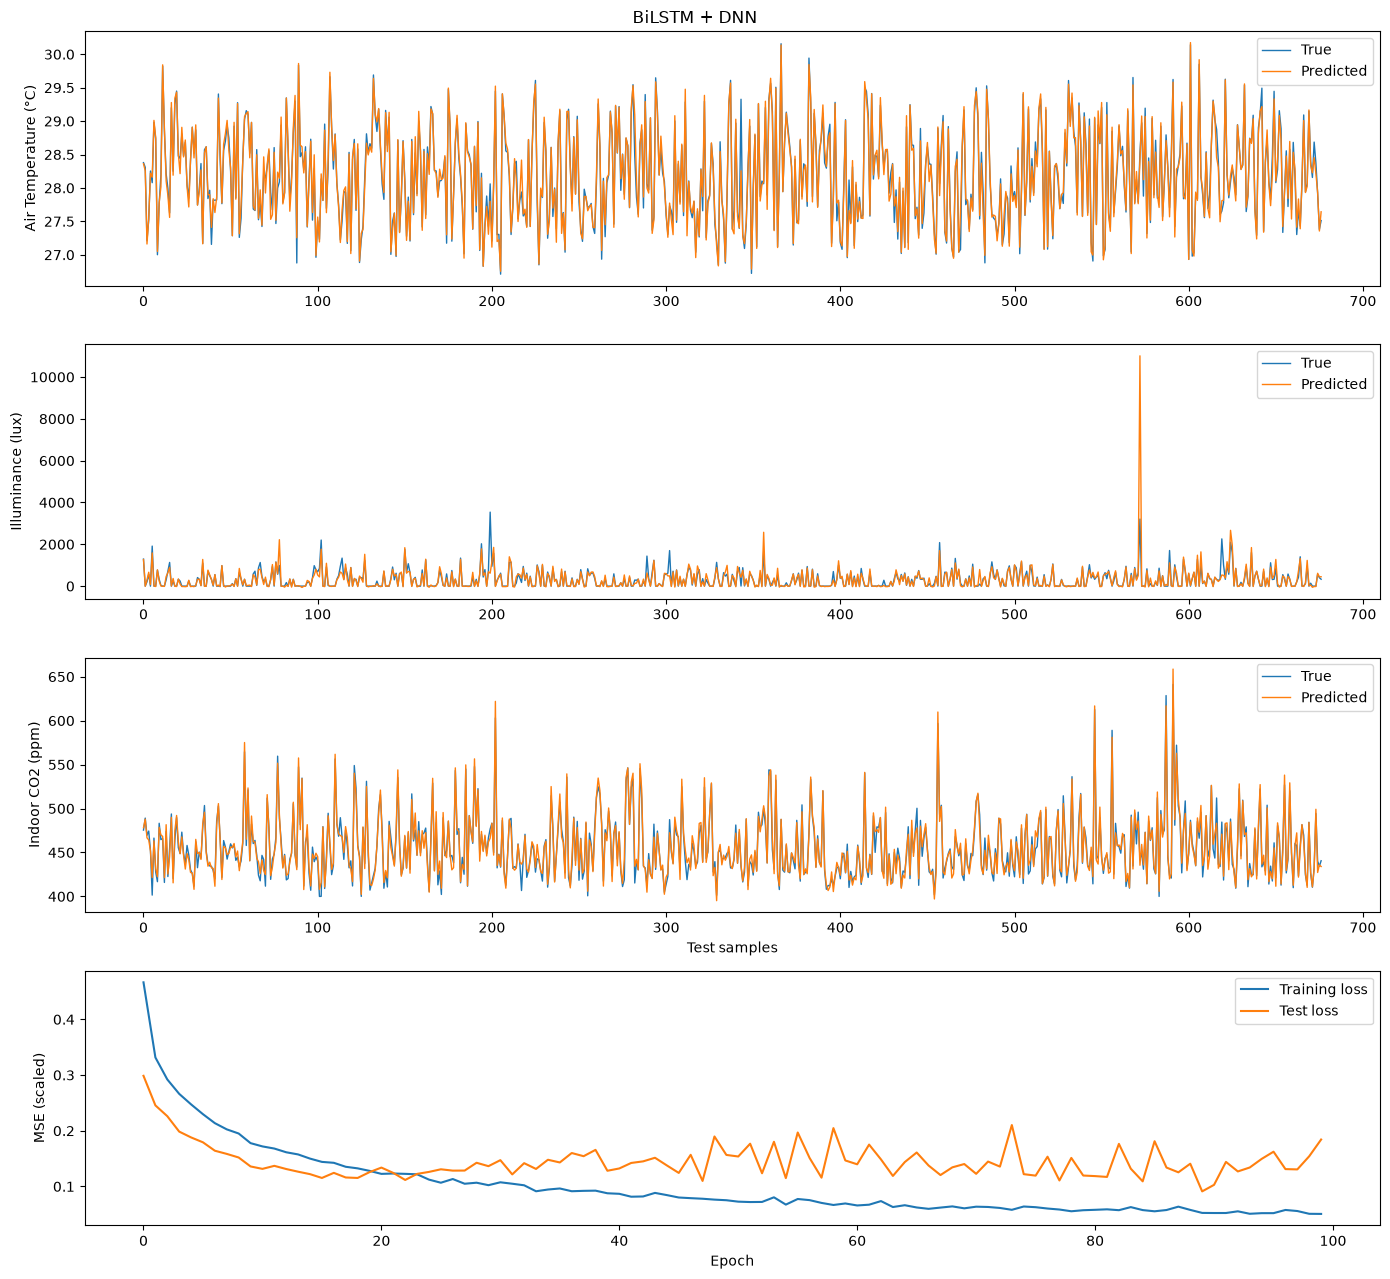

In [10]:
MODEL_NAME = 'BiLSTM + DNN'

# Build the Bidirectional LSTM model with dense layers on top
model = Sequential()
model.add(Input(shape=(X_train.shape[1], X_train.shape[2])))
model.add(Bidirectional(LSTM(100, return_sequences=True)))
model.add(Dropout(0.2))
model.add(Bidirectional(LSTM(100)))
model.add(Dropout(0.2))
model.add(Dense(100, activation='relu'))
model.add(Dense(20, activation='relu'))
model.add(Dense(len(target_columns)))

model.compile(optimizer='adam', loss='mean_squared_error')
model.summary()

# Train the model
history = model.fit(X_train, y_train, epochs=100, batch_size=32,
                    validation_data=(X_test, y_test), verbose=0, shuffle=False)

evaluate_and_plot(model, MODEL_NAME, history)

## 8. Model comparison

In [11]:
comparison = pd.DataFrame(results)
comparison.to_csv(OUTPUT_DIR / 'model_comparison.csv', index=False)
comparison.pivot(index='Model', columns='Target', values='R2').round(4)

Target,air_temperature,illuminance,indoor_co2
Model,,,
BiLSTM + DNN,0.9764,0.3456,0.9673
GRU,0.9655,0.6722,0.9426
LSTM,0.9642,0.6317,0.9520


In [12]:
comparison.pivot(index='Model', columns='Target', values='MAE').round(3)

Target,air_temperature,illuminance,indoor_co2
Model,,,
BiLSTM + DNN,0.071,87.191,4.843
GRU,0.094,88.423,6.219
LSTM,0.090,91.130,5.800
